In [29]:
import os
import numpy as np
import time
import sys
import csv
import cv2
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.backends.cudnn as cudnn
import torchvision
import torchvision.transforms as transforms
import torch.optim as optim
import torch.nn.functional as tfunc
from torch.utils.data import Dataset
from torch.utils.data.dataset import random_split
from torch.utils.data import DataLoader
from torch.optim.lr_scheduler import ReduceLROnPlateau
from PIL import Image
import torch.nn.functional as func

from sklearn.metrics import roc_auc_score
import sklearn.metrics as metrics
import random

use_gpu = torch.cuda.is_available()

In [ ]:

pathFileTrain = 'E:/vision sensor project/CheXpert-v1.0-small/train.csv'
pathFileValid = 'E:/vision sensor project/CheXpert-v1.0-small/valid.csv'


nnIsTrained = False                 
nnClassCount = 14                   #dimension of the output

# Training settings: batch size, maximum number of epochs
trBatchSize = 64
trMaxEpoch = 3

# Parameters related to image transforms: size of the down-scaled image, cropped image
imgtransResize = (320, 320)
imgtransCrop = 224

# Class names
class_names = ['No Finding', 'Enlarged Cardiomediastinum', 'Cardiomegaly', 'Lung Opacity', 
               'Lung Lesion', 'Edema', 'Consolidation', 'Pneumonia', 'Atelectasis', 'Pneumothorax', 
               'Pleural Effusion', 'Pleural Other', 'Fracture', 'Support Devices']

## 1. Create a Dataset


-  **Blanks ('')**: the existence of the pathology is unknown
-  **Ones (1)**: the pathology is detected thanks to the image
-  **Zeros (0)**: the pathology can't be detected thanks to the image
-  **Uncertain (-1)**: the pathology may be detected.

uncertain= 1 (-1->1)

In [3]:
class CheXpertDataSet(Dataset):
    def __init__(self, image_list_file, transform=None, policy="ones"):
        """
        image_list_file: path to the file containing images with corresponding labels.
        transform: optional transform to be applied on a sample.
        Upolicy: name the policy with regard to the uncertain labels
        """
        image_names = []
        labels = []

        with open(image_list_file, "r") as f:
            csvReader = csv.reader(f)
            next(csvReader, None)
            k=0
            for line in csvReader:
                k+=1
                image_name= line[0]
                label = line[5:]
                
                for i in range(14):
                    if label[i]:
                        a = float(label[i])
                        if a == 1:
                            label[i] = 1
                        elif a == -1:
                            if policy == "ones":
                                label[i] = 1
                            elif policy == "zeroes":
                                label[i] = 0
                            else:
                                label[i] = 0
                        else:
                            label[i] = 0
                    else:
                        label[i] = 0
                        
                image_names.append('../' + image_name)
                labels.append(label)

        self.image_names = image_names
        self.labels = labels
        self.transform = transform

    def __getitem__(self, index):
        """Take the index of item and returns the image and its labels"""
        
        image_name = self.image_names[index]
        image = Image.open(image_name).convert('RGB')
        label = self.labels[index]
        if self.transform is not None:
            image = self.transform(image)
        return image, torch.FloatTensor(label)

    def __len__(self):
        return len(self.image_names)

## 2. Create DataLoaders

First we define a transform model to resize all images and normalize them.

In [31]:
#TRANSFORM DATA

normalize = transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
transformList = []
transformList.append(transforms.Resize(imgtransCrop))
transformList.append(transforms.RandomResizedCrop(imgtransCrop))
transformList.append(transforms.RandomHorizontalFlip())
transformList.append(transforms.ToTensor())
transformList.append(normalize)      
transformSequence=transforms.Compose(transformList)

Then we build train, validation and test data loaders. 

In [32]:
#LOAD DATASET

dataset = CheXpertDataSet(pathFileTrain ,transformSequence, policy="ones")
datasetTest, datasetTrain = random_split(dataset, [500, len(dataset) - 500])
datasetValid = CheXpertDataSet(pathFileValid, transformSequence)            


dataLoaderTrain = DataLoader(dataset=datasetTrain, batch_size=trBatchSize, shuffle=True,  num_workers=0, pin_memory=True)
dataLoaderVal = DataLoader(dataset=datasetValid, batch_size=trBatchSize, shuffle=False, num_workers=0, pin_memory=True)
dataLoaderTest = DataLoader(dataset=datasetTest, num_workers=0, pin_memory=True)

## 3. Create train and test Models

We create here a class **CheXpertTrainer** to handle the train and test processes.

In [6]:
class CheXpertTrainer():

    def train (model, dataLoaderTrain, dataLoaderVal, nnClassCount, trMaxEpoch, launchTimestamp, checkpoint):
        
        #SETTINGS: OPTIMIZER & SCHEDULER
        optimizer = optim.Adam (model.parameters(), lr=0.0001, betas=(0.9, 0.999), eps=1e-08, weight_decay=1e-5)
                
        #SETTINGS: LOSS
        loss = torch.nn.BCELoss(size_average = True)
        
        #LOAD CHECKPOINT 
        if checkpoint != None and use_gpu:
            modelCheckpoint = torch.load(checkpoint)
            model.load_state_dict(modelCheckpoint['state_dict'])
            optimizer.load_state_dict(modelCheckpoint['optimizer'])

        
        #TRAIN THE NETWORK
        lossMIN = 100000
        
        for epochID in range(0, trMaxEpoch):
            
            timestampTime = time.strftime("%H%M%S")
            timestampDate = time.strftime("%d%m%Y")
            timestampSTART = timestampDate + '-' + timestampTime
            
            batchs, losst, losse = CheXpertTrainer.epochTrain(model, dataLoaderTrain, optimizer, trMaxEpoch, nnClassCount, loss)
            lossVal = CheXpertTrainer.epochVal(model, dataLoaderVal, optimizer, trMaxEpoch, nnClassCount, loss)


            timestampTime = time.strftime("%H%M%S")
            timestampDate = time.strftime("%d%m%Y")
            timestampEND = timestampDate + '-' + timestampTime
            
            if lossVal < lossMIN:
                lossMIN = lossVal    
                torch.save({'epoch': epochID + 1, 'state_dict': model.state_dict(), 'best_loss': lossMIN, 'optimizer' : optimizer.state_dict()}, 'm-epoch'+str(epochID)+'-' + launchTimestamp + '.pth.tar')
                print ('Epoch [' + str(epochID + 1) + '] [save] [' + timestampEND + '] loss= ' + str(lossVal))
            else:
                print ('Epoch [' + str(epochID + 1) + '] [----] [' + timestampEND + '] loss= ' + str(lossVal))
        
        return batchs, losst, losse        
    #-------------------------------------------------------------------------------- 
       
    def epochTrain(model, dataLoader, optimizer, epochMax, classCount, loss):
        
        batch = []
        losstrain = []
        losseval = []
        
        model.train()

        for batchID, (varInput, target) in enumerate(dataLoaderTrain):
            
            varTarget = target.cuda(non_blocking = True)
            
            #varTarget = target.cuda()         


            varOutput = model(varInput)
            lossvalue = loss(varOutput, varTarget)
                       
            optimizer.zero_grad()
            lossvalue.backward()
            optimizer.step()
            
            l = lossvalue.item()
            losstrain.append(l)
            
            if batchID%35==0:
                print(batchID//35, "% batches computed")
                #Fill three arrays to see the evolution of the loss


                batch.append(batchID)
                
                le = CheXpertTrainer.epochVal(model, dataLoaderVal, optimizer, trMaxEpoch, nnClassCount, loss).item()
                losseval.append(le)
                
                print(batchID)
                print(l)
                print(le)
                
        return batch, losstrain, losseval
    
    #-------------------------------------------------------------------------------- 
    
    def epochVal(model, dataLoader, optimizer, epochMax, classCount, loss):
        
        model.eval()
        
        lossVal = 0
        lossValNorm = 0

        with torch.no_grad():
            for i, (varInput, target) in enumerate(dataLoaderVal):
                
                target = target.cuda(non_blocking = True)
                varOutput = model(varInput)
                
                losstensor = loss(varOutput, target)
                lossVal += losstensor
                lossValNorm += 1
                
        outLoss = lossVal / lossValNorm
        return outLoss
    
    
    #--------------------------------------------------------------------------------     
     
    #---- Computes area under ROC curve 
    #---- dataGT - ground truth data
    #---- dataPRED - predicted data
    #---- classCount - number of classes
    
    def computeAUROC (dataGT, dataPRED, classCount):
        
        outAUROC = []
        
        datanpGT = dataGT.cpu().numpy()
        datanpPRED = dataPRED.cpu().numpy()
        
        for i in range(classCount):
            try:
                outAUROC.append(roc_auc_score(datanpGT[:, i], datanpPRED[:, i]))
            except ValueError:
                pass
        return outAUROC
        
        
    #-------------------------------------------------------------------------------- 
    
    
    def test(model, dataLoaderTest, nnClassCount, checkpoint, class_names):   
        
        cudnn.benchmark = True
        
        if checkpoint != None and use_gpu:
            modelCheckpoint = torch.load(checkpoint)
            model.load_state_dict(modelCheckpoint['state_dict'])

        if use_gpu:
            outGT = torch.FloatTensor().cuda()
            outPRED = torch.FloatTensor().cuda()
        else:
            outGT = torch.FloatTensor()
            outPRED = torch.FloatTensor()
       
        model.eval()
        
        with torch.no_grad():
            for i, (input, target) in enumerate(dataLoaderTest):

                target = target.cuda()
                outGT = torch.cat((outGT, target), 0).cuda()

                bs, c, h, w = input.size()
                varInput = input.view(-1, c, h, w)
            
                out = model(varInput)
                outPRED = torch.cat((outPRED, out), 0)
        aurocIndividual = CheXpertTrainer.computeAUROC(outGT, outPRED, nnClassCount)
        aurocMean = np.array(aurocIndividual).mean()
        
        print ('AUROC mean ', aurocMean)
        
        for i in range (0, len(aurocIndividual)):
            print (class_names[i], ' ', aurocIndividual[i])
        
        return outGT, outPRED

## 4. Train the model

In this part, we train the model and plot the loss curve.

In [7]:
class DenseNet121(nn.Module):
    """Model modified.
    The architecture of our model is the same as standard DenseNet121
    except the classifier layer which has an additional sigmoid function.
    """
    def __init__(self, out_size):
        super(DenseNet121, self).__init__()
        self.densenet121 = torchvision.models.densenet121(pretrained=True)
        num_ftrs = self.densenet121.classifier.in_features
        self.densenet121.classifier = nn.Sequential(
            nn.Linear(num_ftrs, out_size),
            nn.Sigmoid()
        )

    def forward(self, x):
        x = self.densenet121(x)
        return x

In [8]:
# initialize and load the model
model = DenseNet121(nnClassCount)
model = torch.nn.DataParallel(model)

c:\Users\Admin\anaconda3\envs\chexpert_gpu\lib\site-packages\torchvision\models\_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
c:\Users\Admin\anaconda3\envs\chexpert_gpu\lib\site-packages\torchvision\models\_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=DenseNet121_Weights.IMAGENET1K_V1`. You can also use `weights=DenseNet121_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


In [ ]:
timestampTime = time.strftime("%H%M%S")
timestampDate = time.strftime("%d%m%Y")
timestampLaunch = timestampDate + '-' + timestampTime

batch, losst, losse = CheXpertTrainer.train(model, dataLoaderTrain, dataLoaderVal, nnClassCount, trMaxEpoch, timestampLaunch, checkpoint = None)
print("Model trained")

In [ ]:
import torch
import torchvision.models as models

# Define model
model = models.densenet121(pretrained=False)
model.classifier = torch.nn.Linear(model.classifier.in_features, 14)

# Load checkpoint
checkpoint = torch.load("E:/vision sensor project/model_ones_3epoch_densenet", map_location='cpu')

state_dict = checkpoint['state_dict']

new_state_dict = {}

for k, v in state_dict.items():
    # remove DataParallel + model wrapper
    new_key = k.replace("module.densenet121.", "")
    
    
    if new_key == "classifier.0.weight":
        new_key = "classifier.weight"
    elif new_key == "classifier.0.bias":
        new_key = "classifier.bias"
    
    new_state_dict[new_key] = v

# Load weights
model.load_state_dict(new_state_dict)

model.eval()

print("✅ Model loaded successfully")

✅ Model loaded successfully


c:\Users\Admin\anaconda3\envs\chexpert_gpu\lib\site-packages\torchvision\models\_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
c:\Users\Admin\anaconda3\envs\chexpert_gpu\lib\site-packages\torchvision\models\_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)


In [ ]:
import numpy as np
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

y_true = []
y_pred = []

model.eval()

with torch.no_grad():
    for inputs, labels in dataLoaderVal:
        
        inputs = inputs  
        
        outputs = model(inputs)
        probs = torch.sigmoid(outputs)

        y_true.append(labels.numpy())
        y_pred.append(probs.numpy())

y_true = np.concatenate(y_true)
y_pred = np.concatenate(y_pred)

print("✅ Predictions collected")

✅ Predictions collected


In [38]:
# Convert to binary
y_pred_binary = (y_pred > 0.5).astype(int)

accuracy = (y_pred_binary == y_true).mean()

print(f"Accuracy: {accuracy*100:.2f}%")

Accuracy: 84.10%


 Skipping Pneumonia (only one class present)


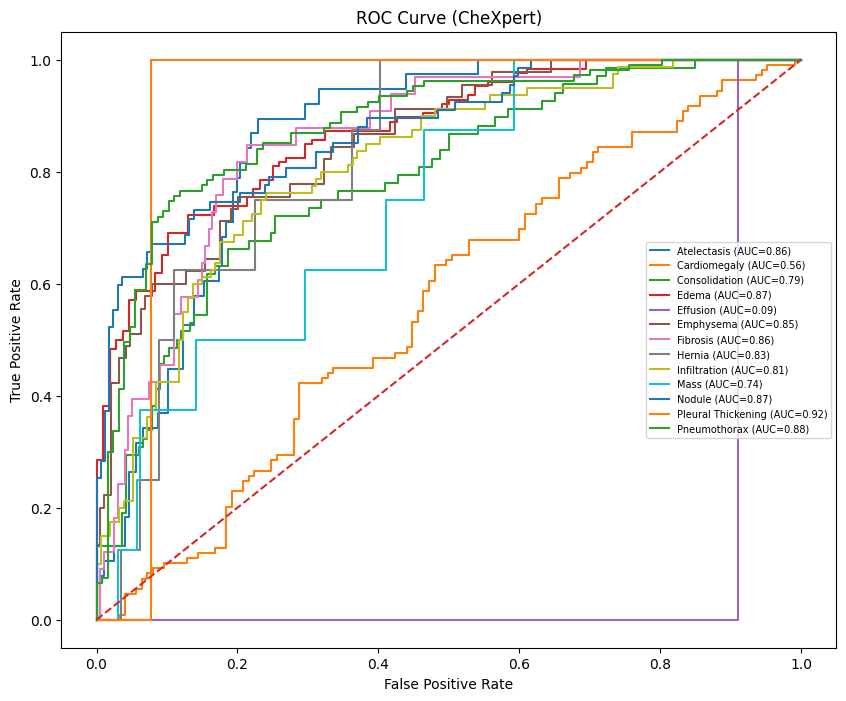

In [39]:
classes = [
    "Atelectasis", "Cardiomegaly", "Consolidation", "Edema",
    "Effusion", "Emphysema", "Fibrosis", "Hernia",
    "Infiltration", "Mass", "Nodule", "Pleural Thickening",
    "Pneumonia", "Pneumothorax"
]

plt.figure(figsize=(10,8))

auc_scores = []

for i in range(len(classes)):
    
    
    if len(np.unique(y_true[:, i])) < 2:
        print(f" Skipping {classes[i]} (only one class present)")
        continue
    
    fpr, tpr, _ = roc_curve(y_true[:, i], y_pred[:, i])
    roc_auc = auc(fpr, tpr)
    auc_scores.append(roc_auc)

    plt.plot(fpr, tpr, label=f"{classes[i]} (AUC={roc_auc:.2f})")

plt.plot([0,1],[0,1],'--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve (CheXpert)")
plt.legend(fontsize=7)
plt.show()

In [37]:
mean_auc = np.mean(auc_scores)
print(f" Mean AUC: {mean_auc:.3f}")

 Mean AUC: 0.765


In [25]:
##INFERENCE

In [22]:
from PIL import Image
import torchvision.transforms as transforms
import torch

# Image transform (VERY IMPORTANT)
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
])

def predict(image_path):
    image = Image.open(image_path).convert('RGB')
    image = transform(image).unsqueeze(0)

    with torch.no_grad():
        output = model(image)
        probs = torch.sigmoid(output)

    return probs.numpy()

In [23]:
import matplotlib.pyplot as plt

def show_image(path):
    img = Image.open(path)
    plt.imshow(img)
    plt.axis('off')
    plt.title("Input Chest X-ray")
    plt.show()

In [ ]:
classes = [
    "Atelectasis", "Cardiomegaly", "Effusion", "Infiltration",
    "Mass", "Nodule", "Pneumonia", "Pneumothorax",
    "Consolidation", "Edema", "Emphysema", "Fibrosis",
    "Pleural Thickening", "Hernia"
]

def show_results(probs):
    print("\n Prediction Results:\n")
    for i in range(len(classes)):
        print(f"{classes[i]:20}: {probs[0][i]:.2f}")

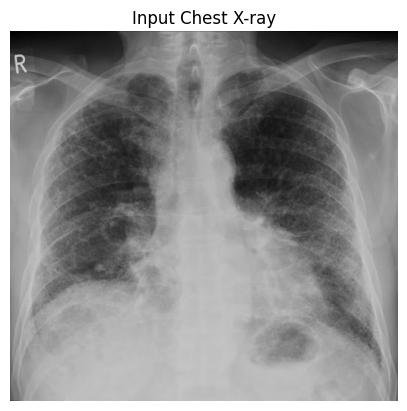


🔍 Prediction Results:

Atelectasis         : 0.03
Cardiomegaly        : 0.09
Effusion            : 0.41
Infiltration        : 0.64
Mass                : 0.09
Nodule              : 0.57
Pneumonia           : 0.25
Pneumothorax        : 0.33
Consolidation       : 0.33
Edema               : 0.03
Emphysema           : 0.25
Fibrosis            : 0.03
Pleural Thickening  : 0.03
Hernia              : 0.07


In [28]:
img_path = "E:/vision sensor project/inference_images/unnamed.jpg"

show_image(img_path)

result = predict(img_path)

show_results(result)